# EDA, Cleaning & Schema Harmonization

In [54]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np
from pathlib import Path
import re
import unicodedata

### Raw Profiling — Dataset Quality Report

The five World Happiness datasets (2015–2019) are inspected to evaluate their data quality. The analysis includes dataset dimensions, data types, missing values, duplicate rows, and numeric columns.

The profiling process is performed **without modifying the original source files**, which remain untouched in `data/raw/`.

**Key observations:**
- 782 total records across five datasets.
- 1 missing value detected in the 2018 dataset.
- No duplicate rows identified.
- Dataset structures vary between 9 and 13 columns.
- Numeric columns range from 8 to 11 per dataset.



In [55]:

# Define dataset directory
DATA_PATH = Path("../../data/raw")

# Initialize report
report = []

# Analyze datasets from 2015 to 2019
for year in range(2015, 2020):
    df = pd.read_csv(DATA_PATH / f"{year}.csv")

    report.append({
        "year": year,
        "rows": df.shape[0],
        "cols": df.shape[1],
        "null_cells": df.isnull().sum().sum(),
        "dup_rows": df.duplicated().sum(),
        "numeric_cols": df.select_dtypes(include="number").shape[1]
    })

# Create DataFrame
quality_report = pd.DataFrame(report)

# Display results
display(quality_report)

# Calculate totals
print("TOTAL rows:", quality_report["rows"].sum())
print("TOTAL null cells:", quality_report["null_cells"].sum())
print("TOTAL duplicate rows:", quality_report["dup_rows"].sum())

,year,rows,cols,null_cells,dup_rows,numeric_cols
0,2015,158,12,0,0,10
1,2016,157,13,0,0,11
2,2017,155,12,0,0,11
3,2018,156,9,1,0,8
4,2019,156,9,0,0,8


TOTAL rows: 782
TOTAL null cells: 1
TOTAL duplicate rows: 0


# Inconsistent column names

In [56]:



# Display all rows and columns without truncation
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)


# 1. Normalize column names
def normalize_column(column):
    column = unicodedata.normalize("NFKD", str(column))
    column = column.encode("ascii", "ignore").decode("utf-8")
    column = column.lower()
    column = re.sub(r"[^a-z0-9]+", "_", column)

    return column.strip("_")


# 2. Normalize columns for each year
# Load each year's raw dataset before normalizing its column names
raw = {
    year: pd.read_csv(DATA_PATH / f"{year}.csv")
    for year in range(2015, 2020)
}

normalized_columns = {
    year: {
        column: normalize_column(column)
        for column in df.columns
    }
    for year, df in sorted(raw.items())
}


# 3. Detect matching column names across years
column_matches = {}

for year, columns in normalized_columns.items():
    for original_name, normalized_name in columns.items():
        column_matches.setdefault(normalized_name, set()).add(original_name)


# 4. Build the schema presence matrix
schema = pd.DataFrame(
    {
        year: {
            column: "✓"
            for column in df.columns
        }
        for year, df in sorted(raw.items())
    }
).fillna("")


# 5. Assign normalized names to the schema
schema["unified_name"] = [
    normalize_column(column)
    for column in schema.index
]


# 6. Sort schema by normalized column name
schema = schema.sort_values(
    by="unified_name",
    kind="stable"
)


# 7. Build the data type matrix
data_types = pd.DataFrame(
    {
        year: {
            column: str(dtype)
            for column, dtype in df.dtypes.items()
        }
        for year, df in sorted(raw.items())
    }
).fillna("")


# 8. Assign normalized names to the data type matrix
data_types["unified_name"] = [
    normalize_column(column)
    for column in data_types.index
]

data_types = data_types.sort_values(
    by="unified_name",
    kind="stable"
)


# 9. Analyze data type inconsistencies
type_analysis = {}

for year, df in sorted(raw.items()):
    for column, dtype in df.dtypes.items():
        normalized_name = normalize_column(column)

        type_analysis.setdefault(
            normalized_name, {}
        ).setdefault(str(dtype), set()).add(year)


# 10. Generate a data type inconsistency report
type_inconsistencies = []

for column, types in type_analysis.items():
    if len(types) > 1:
        type_inconsistencies.append({
            "column": column,
            "data_types": {
                dtype: sorted(years)
                for dtype, years in types.items()
            }
        })


# 11. Analyze schema differences
schema_analysis = []

years = sorted(raw.keys())

for column in schema.index:
    available_years = [
        year for year in years
        if column in raw[year].columns
    ]

    missing_years = [
        year for year in years
        if column not in raw[year].columns
    ]

    schema_analysis.append({
        "column": column,
        "unified_name": normalize_column(column),
        "available_years": available_years,
        "missing_years": missing_years,
        "presence_count": len(available_years)
    })


schema_analysis = pd.DataFrame(schema_analysis)


# 12. Display analysis results
print("\n=== SCHEMA PRESENCE MATRIX ===")
display(schema)

print("\n=== DATA TYPE MATRIX ===")
display(data_types)

print("\n=== DATA TYPE INCONSISTENCIES ===")
if type_inconsistencies:
    display(pd.DataFrame(type_inconsistencies))
else:
    print("No data type inconsistencies detected.")


print("\n=== SCHEMA DIFFERENCES ===")
display(schema_analysis)



=== SCHEMA PRESENCE MATRIX ===


,2015,2016,2017,2018,2019,unified_name
Country,✓,✓,✓,,,country
Country or region,,,,✓,✓,country_or_region
Dystopia Residual,✓,✓,,,,dystopia_residual
Dystopia.Residual,,,✓,,,dystopia_residual
Economy (GDP per Capita),✓,✓,,,,economy_gdp_per_capita
Economy..GDP.per.Capita.,,,✓,,,economy_gdp_per_capita
Family,✓,✓,✓,,,family
Freedom,✓,✓,✓,,,freedom
Freedom to make life choices,,,,✓,✓,freedom_to_make_life_choices
GDP per capita,,,,✓,✓,gdp_per_capita



=== DATA TYPE MATRIX ===


,2015,2016,2017,2018,2019,unified_name
Country,object,object,object,,,country
Country or region,,,,object,object,country_or_region
Dystopia Residual,float64,float64,,,,dystopia_residual
Dystopia.Residual,,,float64,,,dystopia_residual
Economy (GDP per Capita),float64,float64,,,,economy_gdp_per_capita
Economy..GDP.per.Capita.,,,float64,,,economy_gdp_per_capita
Family,float64,float64,float64,,,family
Freedom,float64,float64,float64,,,freedom
Freedom to make life choices,,,,float64,float64,freedom_to_make_life_choices
GDP per capita,,,,float64,float64,gdp_per_capita



=== DATA TYPE INCONSISTENCIES ===
No data type inconsistencies detected.

=== SCHEMA DIFFERENCES ===


,column,unified_name,available_years,missing_years,presence_count
0,Country,country,"[2015, 2016, 2017]","[2018, 2019]",3
1,Country or region,country_or_region,"[2018, 2019]","[2015, 2016, 2017]",2
2,Dystopia Residual,dystopia_residual,"[2015, 2016]","[2017, 2018, 2019]",2
3,Dystopia.Residual,dystopia_residual,[2017],"[2015, 2016, 2018, 2019]",1
4,Economy (GDP per Capita),economy_gdp_per_capita,"[2015, 2016]","[2017, 2018, 2019]",2
5,Economy..GDP.per.Capita.,economy_gdp_per_capita,[2017],"[2015, 2016, 2018, 2019]",1
6,Family,family,"[2015, 2016, 2017]","[2018, 2019]",3
7,Freedom,freedom,"[2015, 2016, 2017]","[2018, 2019]",3
8,Freedom to make life choices,freedom_to_make_life_choices,"[2018, 2019]","[2015, 2016, 2017]",2
9,GDP per capita,gdp_per_capita,"[2018, 2019]","[2015, 2016, 2017]",2


### Schema Harmonization – World Happiness Report (2015–2019)

The datasets use different column names across years. The following mapping identifies equivalent variables and their corresponding canonical names for schema harmonization.

| 2015–2016 | 2017 | 2018–2019 | Conceptual Variable |
|---|---|---|---|
| `Country` | `Country` | `Country or region` | `country` |
| `Happiness Rank` | `Happiness.Rank` | `Overall rank` | `happiness_rank` |
| `Happiness Score` | `Happiness.Score` | `Score` | `happiness_score` |
| `Economy (GDP per Capita)` | `Economy..GDP.per.Capita.` | `GDP per capita` | `gdp` |
| `Family` | `Family`| `Social support` | `social_support` |
| `Health (Life Expectancy)` | `Health..Life.Expectancy.` | `Healthy life expectancy` | `health` |
| `Freedom` | `Freedom` | `Freedom to make life choices` | `freedom` |
| `Trust (Government Corruption)` | `Trust..Government.Corruption.` | `Perceptions of corruption` | `corruption` |

**Note:** The mapping establishes a common naming convention for equivalent conceptual variables across different dataset versions. Differences in measurement definitions and methodologies should be considered before comparing values across years.

# 2. Standardize column names

In [57]:
RENAME = {
    2015: {
        "Country": "country",
        "Happiness Rank": "happiness_rank",
        "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp_per_capita",
        "Family": "social_support",
        "Health (Life Expectancy)": "healthy_life_expectancy",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "perceptions_of_corruption"
    },
    2016: {
        "Country": "country",
        "Happiness Rank": "happiness_rank",
        "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp_per_capita",
        "Family": "social_support",
        "Health (Life Expectancy)": "healthy_life_expectancy",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "perceptions_of_corruption"
    },
    2017: {
        "Country": "country",
        "Happiness.Rank": "happiness_rank",
        "Happiness.Score": "happiness_score",
        "Economy..GDP.per.Capita.": "gdp_per_capita",
        "Family": "social_support",
        "Health..Life.Expectancy.": "healthy_life_expectancy",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust..Government.Corruption.": "perceptions_of_corruption"
    },
    2018: {
        "Overall rank": "happiness_rank",
        "Country or region": "country",
        "Score": "happiness_score",
        "GDP per capita": "gdp_per_capita",
        "Social support": "social_support",
        "Healthy life expectancy": "healthy_life_expectancy",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "perceptions_of_corruption"
    },
    2019: {
        "Overall rank": "happiness_rank",
        "Country or region": "country",
        "Score": "happiness_score",
        "GDP per capita": "gdp_per_capita",
        "Social support": "social_support",
        "Healthy life expectancy": "healthy_life_expectancy",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "perceptions_of_corruption"
    }
}

In [58]:
standardized = {}

for year, df in sorted(raw.items()):
    standardized[year] = df.rename(
        columns=RENAME[year]
    ).copy()

# 3. Standardize data types

In [59]:
DTYPES = {
    "country": "string",
    "year": "int64",
    "happiness_rank": "Int64",
    "happiness_score": "float64",
    "gdp_per_capita": "float64",
    "social_support": "float64",
    "healthy_life_expectancy": "float64",
    "freedom": "float64",
    "generosity": "float64",
    "perceptions_of_corruption": "float64"
}

for year, df in standardized.items():

    df["year"] = year

    for column, dtype in DTYPES.items():

        if column not in df.columns:
            df[column] = pd.NA

        if dtype == "string":
            df[column] = df[column].astype("string")

        elif dtype == "Int64":
            df[column] = pd.to_numeric(
                df[column], errors="coerce"
            ).astype("Int64")

        elif dtype == "float64":
            df[column] = pd.to_numeric(
                df[column], errors="coerce"
            ).astype("float64")

        else:
            df[column] = df[column].astype(dtype)

#  Merge datasets into a unified dataset

In [60]:
STANDARD_COLUMNS = list(DTYPES.keys())

unified_df = pd.concat(
    [
        df[STANDARD_COLUMNS]
        for year, df in sorted(standardized.items())
    ],
    ignore_index=True
)

In [61]:
print("=== UNIFIED DATASET ===")

display(unified_df.head())

print("\n=== DATASET SHAPE ===")
print(unified_df.shape)

print("\n=== DATA TYPES ===")
print(unified_df.dtypes)

print("\n=== MISSING VALUES ===")
display(unified_df.isnull().sum().to_frame("missing_count"))

print("\n=== DUPLICATED RECORDS ===")
print(unified_df.duplicated().sum())

print("\n=== RECORDS PER YEAR ===")
print(unified_df["year"].value_counts().sort_index())

=== UNIFIED DATASET ===


,country,year,happiness_rank,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom,generosity,perceptions_of_corruption
0,Switzerland,2015,1,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,2015,2,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,2015,3,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,2015,4,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,2015,5,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957



=== DATASET SHAPE ===
(782, 10)

=== DATA TYPES ===
country                      string[python]
year                                  int64
happiness_rank                        Int64
happiness_score                     float64
gdp_per_capita                      float64
social_support                      float64
healthy_life_expectancy             float64
freedom                             float64
generosity                          float64
perceptions_of_corruption           float64
dtype: object

=== MISSING VALUES ===


,missing_count
country,0
year,0
happiness_rank,0
happiness_score,0
gdp_per_capita,0
social_support,0
healthy_life_expectancy,0
freedom,0
generosity,0
perceptions_of_corruption,1



=== DUPLICATED RECORDS ===
0

=== RECORDS PER YEAR ===
year
2015    158
2016    157
2017    155
2018    156
2019    156
Name: count, dtype: int64


In [62]:
import pandas as pd

# Create a copy to preserve the original dataset
df_analysis = unified_df.copy()

# Standardize country names
df_analysis["country"] = (
    df_analysis["country"]
    .astype("string")
    .str.strip()
)

# Convert year to numeric
df_analysis["year"] = pd.to_numeric(
    df_analysis["year"],
    errors="coerce"
)

# Define expected years
expected_years = set(range(2015, 2020))

# Group data by country
country_participation = (
    df_analysis.dropna(subset=["country", "year"])
    .groupby("country")
    .agg(
        participation_count=("year", "nunique"),
        participation_years=(
            "year",
            lambda x: sorted(x.unique().astype(int).tolist())
        ),
        total_records=("year", "count")
    )
    .reset_index()
)

# Identify missing participation years
country_participation["missing_years"] = (
    country_participation["participation_years"]
    .apply(lambda years: sorted(expected_years - set(years)))
)

# Identify participation consistency
country_participation["participation_status"] = (
    country_participation["participation_count"]
    .apply(
        lambda count: "Complete" if count == len(expected_years)
        else "Incomplete"
    )
)

# Sort results
country_participation = country_participation.sort_values(
    by=["participation_count", "country"],
    ascending=[False, True]
).reset_index(drop=True)

# Display results
display(country_participation)

,country,participation_count,participation_years,total_records,missing_years,participation_status
0,Afghanistan,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
1,Albania,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
2,Algeria,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
3,Argentina,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
4,Armenia,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
5,Australia,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
6,Austria,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
7,Azerbaijan,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
8,Bahrain,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
9,Bangladesh,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete


In [63]:
# Create a working copy
df_clean = unified_df.copy()

# Standardize text formatting
df_clean["country"] = (
    df_clean["country"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Define country name mappings
country_mapping = {
    "Macedonia": "North Macedonia",
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Somaliland region": "Somaliland Region",
    "Northern Cyprus": "North Cyprus",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Swaziland": "Eswatini"
}

# Apply standardization
df_clean["country"] = df_clean["country"].replace(country_mapping)

# Check unique country names
print("Unique countries after standardization:")
print(df_clean["country"].nunique())

display(
    df_clean["country"]
    .value_counts()
    .to_frame("record_count")
)

Unique countries after standardization:
164


,record_count
country,
Switzerland,5
Iceland,5
Denmark,5
Norway,5
Canada,5
Finland,5
Netherlands,5
Sweden,5
New Zealand,5


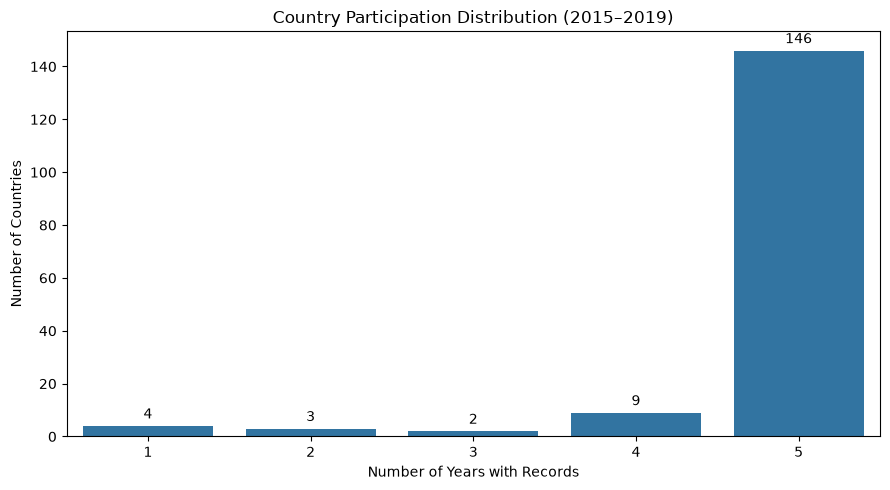

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the number of countries by participation count
participation_distribution = (
    df_clean["country"]
    .value_counts()
    .value_counts()
    .sort_index()
)

# Create the bar chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=participation_distribution.index,
    y=participation_distribution.values
)

plt.title("Country Participation Distribution (2015–2019)")
plt.xlabel("Number of Years with Records")
plt.ylabel("Number of Countries")

# Add labels above each bar
ax.bar_label(ax.containers[0], padding=3)

plt.xticks(range(5), [1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

In [65]:
# Check whether any original country names remain in the mapping
remaining_aliases = set(country_mapping.keys()).intersection(
    set(df_clean["country"].dropna().unique())
)

print("Remaining country aliases:", remaining_aliases)

# Validate total records and unique countries
print("Total records:", len(df_clean))
print("Unique countries:", df_clean["country"].nunique())

Remaining country aliases: set()
Total records: 782
Unique countries: 164


In [66]:
expected_years = set(range(2015, 2020))

country_participation_clean = (
    df_clean.dropna(subset=["country", "year"])
    .groupby("country")
    .agg(
        participation_count=("year", "nunique"),
        participation_years=(
            "year",
            lambda x: sorted(x.unique().astype(int).tolist())
        ),
        total_records=("year", "count")
    )
    .reset_index()
)

country_participation_clean["missing_years"] = (
    country_participation_clean["participation_years"]
    .apply(lambda x: sorted(expected_years - set(x)))
)

country_participation_clean["participation_status"] = (
    country_participation_clean["participation_count"]
    .apply(lambda x: "Complete" if x == 5 else "Incomplete")
)

display(
    country_participation_clean.sort_values(
        ["participation_count", "country"],
        ascending=[False, True]
    )
)

,country,participation_count,participation_years,total_records,missing_years,participation_status
0,Afghanistan,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
1,Albania,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
2,Algeria,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
4,Argentina,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
5,Armenia,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
6,Australia,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
7,Austria,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
8,Azerbaijan,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
9,Bahrain,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete
10,Bangladesh,5,"[2015, 2016, 2017, 2018, 2019]",5,[],Complete


### Data Cleaning and Validation

The five World Happiness Report datasets (2015–2019) were standardized and unified into a single dataset.

The following data cleaning and validation steps were performed:

1. **Country name standardization:** Country names were cleaned by removing leading and trailing spaces, normalizing whitespace, and applying a mapping to standardize inconsistent country names (e.g., Swaziland to Eswatini).
2. **Dataset unification:** The five yearly datasets were combined into a single DataFrame with standardized columns.
3. **Country participation analysis:** Country participation across the five years was examined. A total of 164 countries and territories were identified, of which 146 had records for all five years.
4. **Missing participation analysis:** Eighteen entities had incomplete year coverage. These records were retained because missing participation does not necessarily indicate a data quality issue.
5. **Duplicate validation:** No duplicate country-year combinations were found.

The resulting dataset contains **782 records and 164 unique country and territory labels**. No records were removed during country name standardization or participation validation.

The dataset is now ready for the next stage: missing-value analysis and exploratory data analysis (EDA).

In [67]:
# Check corruption perception values for UAE across all years
uae_data = df_clean[
    df_clean['country'] == 'United Arab Emirates'
][['year', 'perceptions_of_corruption']].sort_values('year')

print(uae_data)

# Identify years with null values
null_years = uae_data[
    uae_data['perceptions_of_corruption'].isna()
]['year'].tolist()

print("\nYears with null values:")
print(null_years if null_years else "No null values found.")

     year  perceptions_of_corruption
19   2015                    0.38583
185  2016                    0.35561
335  2017                    0.32449
489  2018                        NaN
646  2019                    0.18200

Years with null values:
[2018]


## Missing Value Treatment – Linear Interpolation

A single missing value was identified for **United Arab Emirates (UAE)** in 2018 within the `perceptions_of_corruption` variable.

Linear interpolation was selected because the observations from the previous year (2017) and the following year (2019) were available. This method estimates the missing value based on the temporal distance between the two observations, preserving the country's record without introducing a global average.

The estimated value is not an original measurement and should be interpreted with caution.

### Statistical Calculation

Linear interpolation estimates an unknown value using two known observations. The following formula was applied:

$$
Y_t = Y_0 + \frac{t-t_0}{t_1-t_0}(Y_1-Y_0)
$$

**Where:**

- $Y_0$: Known value from 2017.
- $Y_1$: Known value from 2019.
- $t_0$: Initial year (2017).
- $t_1$: Final year (2019).
- $t$: Year being estimated (2018).

**Substituting the available values:**

$$
Y_{2018} = 0.32449 +
\frac{2018-2017}{2019-2017}
(0.18200-0.32449)
$$

**Calculation:**

$$
Y_{2018} = 0.32449 + 0.5(-0.14249)
$$

**Estimated result:**

$$
\boxed{Y_{2018} = 0.253245}
$$

### Final Result

| Year | Perceptions of Corruption | Status |
|---|---:|---|
| 2017 | 0.32449 | Original value |
| 2018 | 0.253245 | Estimated (interpolation) |
| 2019 | 0.18200 | Original value |

**Conclusion:** Linear interpolation was used to handle the missing observation while preserving the temporal structure of the dataset. The estimated value was retained for further data analysis, with its imputed nature documented.

In [68]:
# Interpolate missing values for UAE
uae_mask = df_clean['country'] == 'United Arab Emirates'

df_clean.loc[uae_mask, 'perceptions_of_corruption'] = (
    df_clean.loc[uae_mask, 'perceptions_of_corruption']
    .interpolate(method='linear')
)

In [69]:
# Verify UAE values
print(
    df_clean.loc[
        uae_mask,
        ['year', 'perceptions_of_corruption']
    ].sort_values('year')
)

     year  perceptions_of_corruption
19   2015                   0.385830
185  2016                   0.355610
335  2017                   0.324490
489  2018                   0.253245
646  2019                   0.182000


In [70]:
# Check missing values in the cleaned dataset
print(df_clean.isnull().sum())

country                      0
year                         0
happiness_rank               0
happiness_score              0
gdp_per_capita               0
social_support               0
healthy_life_expectancy      0
freedom                      0
generosity                   0
perceptions_of_corruption    0
dtype: int64


In [71]:
from pathlib import Path

# Define the processed data directory
processed_dir = Path("../../data/processed")

# Create the directory if it does not exist
processed_dir.mkdir(parents=True, exist_ok=True)

# Export the cleaned dataset
output_path = processed_dir / "world_happiness_2015_2019_clean.csv"

df_clean.to_csv(
    output_path,
    index=False,
    encoding="utf-8"
)

print(f"Cleaned dataset saved to: {output_path}")
print(f"Dataset shape: {df_clean.shape}")

Cleaned dataset saved to: ../../data/processed/world_happiness_2015_2019_clean.csv
Dataset shape: (782, 10)
